# Comparison: `fastpiclef` vs the reference codes

A reproducible, single-machine comparison of the wave-optics Fresnel-integral solvers in `refs/`
against `fastpiclef`. This notebook **runs the harness live** and compiles all results.

The reference codes are compared one at a time, each in the protocol it is built for — so the
notebook is organised **by reference code**:

| part | reference code | kind | protocol |
|---|---|---|---|
| **A** | [`plind`](https://pypi.org/project/plind/) | Python, PL flow | single source position at a time |
| **B** | `P-LPI` (`refs/P-LPI`) | C++, PL flow | a whole grid of source positions at once |
| **C** | `FIONA` (`refs/FIONA`) | Python, GL + FINUFFT | frequency sweep (point mass) + a 2-D field |

**Shared test case.** Both parts exercise the *same* lens family — `RationalLens(kappa=-2)`,
$\phi=(x-\mu)^2/2 + 2/(1+x^2)$, at $\omega=\nu=10$ (P-LPI's hardcoded benchmark). Part A hits it at a
single source position (alongside two other cases); Part B sweeps its source position into a full
512-point grid. So `plind` is graded on it single-point **and** on the grid, giving a common thread
through both parts.

**Method & fairness**
* Compared quantity: the raw integral $\int e^{i\omega\phi}\,dx$ (convention-free; the amplification
  $F$ is a fixed rescaling of it).
* **Truth**: our machine-precision *thimble* result, independently validated — it agrees with a
  method-independent brute-force referee (raw-integrand quadrature + exact Fresnel tails) to that
  referee's ~$10^{-6}$ floor, and with the exact Airy function to $3\times10^{-15}$. Grading an
  *independent* code against it is fair.
* **Single-threaded** (`RAYON_NUM_THREADS = OMP_NUM_THREADS = 1`); threaded speed is a separate axis.

*Run in the env that has both Jupyter and the reference codes:* `pixi run -e notebook lab`, or
headless via `pixi run notebook-comparison`.

In [1]:
import os, sys
root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(root, 'pyproject.toml')) and root != '/':
    root = os.path.dirname(root)
sys.path.insert(0, root); os.chdir(root)

import comparison.run as H          # sets single-thread pin, then imports fastpiclef
import comparison.cases as C
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print('repo root :', root)
print('threads   : RAYON =', os.environ.get('RAYON_NUM_THREADS'), ' OMP =', os.environ.get('OMP_NUM_THREADS'))
print('cases     :', [c.name for c in C.CASES])

repo root : /home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code
threads   : RAYON = 1  OMP = 1
cases     : ['rational b=0.3 k=-2.0 w=10', 'rational b=0.3 k=0.2 w=1', 'airy y=1.0 w=1']


## Part A — versus `plind` (Python PL flow · single-point protocol)

`plind` solves one source position per call. We compare on three cases: the shared
`RationalLens(k=-2, w=10)` (strong, multi-image — P-LPI's lens), a gentle diverging lens, and the
Airy (cubic) phase whose exact value anchors the accuracy scale.

### A.1 — Reference sanity: is our 'truth' trustworthy?

Our thimble truth vs the independent brute-force referee. They agree down to the referee's own
~$10^{-6}$ floor (its analytic tail neglects the potential's tail), which is why it is used only as a
cross-check, not to grade sub-$10^{-6}$ solvers. (For Airy the truth *is* the exact Airy function.)

In [2]:
san = pd.DataFrame(
    [(c.name, H.rel(c.truth, c.referee)) for c in C.CASES],
    columns=['case', 'thimble vs brute-force referee (rel.)'])
(san.style.format({'thimble vs brute-force referee (rel.)': '{:.1e}'})
    .hide(axis='index')
    .set_caption('A.1 — Truth cross-check: thimble vs independent referee'))

case,thimble vs brute-force referee (rel.)
rational b=0.3 k=-2.0 w=10,3.3e-05
rational b=0.3 k=0.2 w=1,2.2e-06
airy y=1.0 w=1,0.0e+00


### A.2 — Accuracy & speed (single-threaded)

Relative error (vs the validated truth) and median wall time over repetitions, across the three
cases. The first, `rational b=0.3 k=-2 w=10`, **is** P-LPI's lens at a single source position —
Part B sweeps it into a grid.

In [3]:
df = H.summary_table()            # runs fastpiclef (thimble+mesh) and plind on each case
tbl = df.rename(columns={'solver': 'method', 'rel_err': 'relative error'})
tbl['wall time (ms)'] = tbl['time_s'] * 1e3
(tbl[['case', 'method', 'relative error', 'wall time (ms)']]
    .style.format({'relative error': '{:.2e}', 'wall time (ms)': '{:.2f}'})
    .hide(axis='index')
    .set_caption('A.2 — Accuracy (rel. error vs validated truth) and single-thread wall time'))

/home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code/.pixi/envs/notebook/lib/python3.14/site-packages/plind/descend/core.py:34: RuntimeWarning: divide by zero encountered in divide
  delta = np.min((np.divide(tol, 2*R))**(1/4))


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961
total steps: 12 current time: 1.5658250587466271


total steps: 12 current time: 1.5658250587466271
total steps: 12 current time: 1.5658250587466271


... (2 outputs left out)

total steps: 91 current time: 1.5137474099313217


total steps: 91 current time: 1.5137474099313217


total steps: 91 current time: 1.5137474099313217


case,method,relative error,wall time (ms)
rational b=0.3 k=-2.0 w=10,fastpiclef/auto,0.00e+00,0.48
rational b=0.3 k=-2.0 w=10,fastpiclef/mesh,7.22e-15,4.03
rational b=0.3 k=-2.0 w=10,plind,6.64e-03,2369.31
rational b=0.3 k=0.2 w=1,fastpiclef/auto,0.00e+00,0.31
rational b=0.3 k=0.2 w=1,fastpiclef/mesh,1.68e-13,7.76
rational b=0.3 k=0.2 w=1,plind,2.95e-10,137.79
airy y=1.0 w=1,fastpiclef/auto,2.90e-15,0.24
airy y=1.0 w=1,fastpiclef/mesh,6.60e-16,3.73
airy y=1.0 w=1,plind,2.12e-07,477.76


#### Headline: `fastpiclef` (auto) vs `plind`

In [4]:
piv = df.pivot_table(index='case', columns='solver', values='time_s')
head = pd.DataFrame({
    'plind time (s)': piv['plind'],
    'fastpiclef time (ms)': piv['fastpiclef/auto'] * 1e3,
    'speedup': piv['plind'] / piv['fastpiclef/auto'],
})
(head.style.format({'plind time (s)': '{:.3f}', 'fastpiclef time (ms)': '{:.2f}', 'speedup': '{:.0f}x'})
    .set_caption('Headline: single-point speedup, fastpiclef (auto) vs plind'))

,plind time (s),fastpiclef time (ms),speedup
case,,,
airy y=1.0 w=1,0.478,0.24,1961x
rational b=0.3 k=-2.0 w=10,2.369,0.48,4970x
rational b=0.3 k=0.2 w=1,0.138,0.31,438x


### A.3 — The real differentiator: error vs cost

How accuracy scales with wall time (the resolution knob is swept for each flow method). `fastpiclef`
sits at the bottom-left (fast **and** machine-precise — the adaptive stopping means the mesh does not
trade accuracy for cost); `plind` at the top-right. The thimble ★ is the reference (fastest, exact).

total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.539269997668487
total steps: 32 current time: 1.539269997668487


total steps: 32 current time: 1.539269997668487
total steps: 32 current time: 1.539269997668487


total steps: 32 current time: 1.5382943964986286
total steps: 32 current time: 1.5382943964986286


total steps: 32 current time: 1.5382943964986286
total steps: 32 current time: 1.5382943964986286


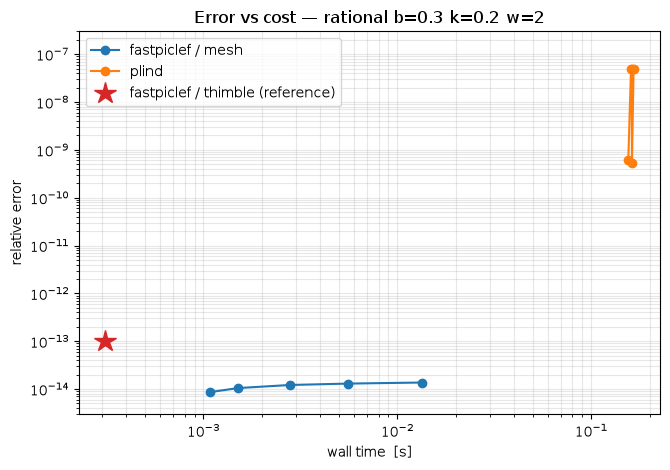

In [5]:
case, series, thimble_pt = H.convergence_curve()
fig, ax = plt.subplots(figsize=(6.8, 4.8))
H.plot_convergence(ax, case, series, thimble_pt)
plt.tight_layout(); plt.show()

## Part B — versus `P-LPI` (C++ PL flow · grid protocol)

`P-LPI` (`refs/P-LPI/code_1D`) natively computes a whole *grid* of source positions at once. Its
hardcoded case is exactly the shared lens — `RationalLens(kappa=-2)` at $\nu=10$ — over
$\mu\in[-4,4]$ (512 points). This gives a **third independent PL cross-check** (from a code we did
not write) and the natural setting for the *grid* protocol. It amortises by reusing 32 thimbles
across the 512 points (a built-in warm-start).

All three codes run the **same grid** here: `fastpiclef` (512 independent solves), `P-LPI` (batched),
and `plind` (subsampled — it is ~1 s/point). So `plind`, tested single-point in Part A, is re-tested
on the grid here — the shared lens tying the two parts together. Below: $|F(\mu)|$ from all three
(they overlay — the 3-way agreement), then each code's accuracy across the grid vs the fastpiclef
thimble reference.

/home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code/.pixi/envs/notebook/lib/python3.14/site-packages/plind/descend/core.py:34: RuntimeWarning: divide by zero encountered in divide
  delta = np.min((np.divide(tol, 2*R))**(1/4))


total steps: 217 current time: 1.5094399028579584


total steps: 259 current time: 1.5045485142936434


total steps: 325 current time: 1.5040719615227194


total steps: 504 current time: 1.5022236892905385


total steps: 2952 current time: 1.5003858771374787


... (6 outputs left out)

total steps: 742 current time: 1.5026244292867499


total steps: 325 current time: 1.5040702993888253


total steps: 267 current time: 1.5104593346792017


total steps: 217 current time: 1.509442333623943


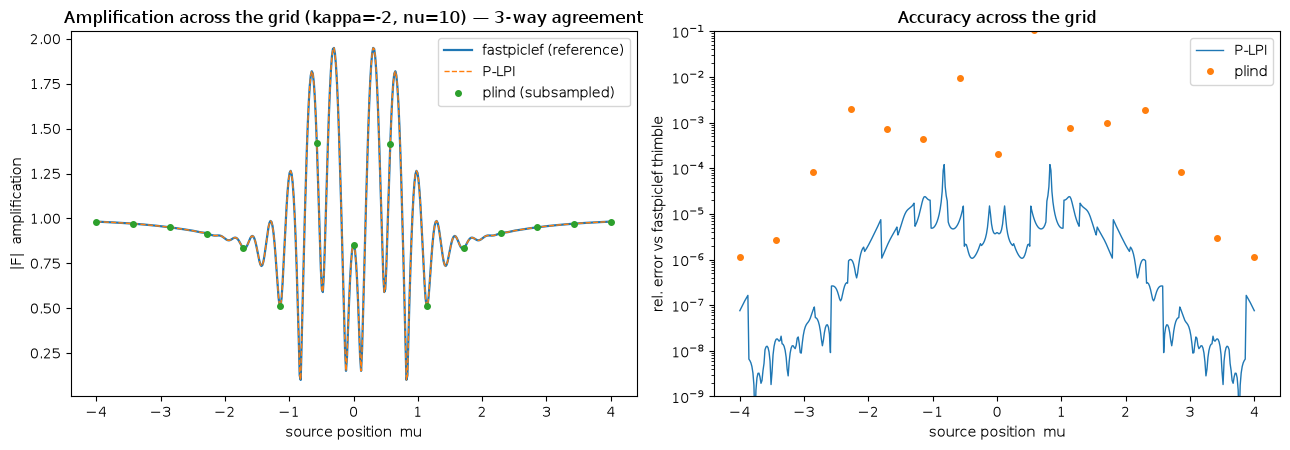

In [6]:
res = H.grid_comparison()   # builds+runs P-LPI, loops fastpiclef, subsamples plind (~30 s)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
H.plot_grid_overlay(a1, res)
H.plot_grid_error(a2, res)
plt.tight_layout(); plt.show()

In [7]:
(pd.DataFrame(res['times'].items(), columns=['configuration', 'wall time (s)'])
    .style.format({'wall time (s)': '{:.3f}'})
    .hide(axis='index')
    .set_caption('B — Grid wall time, 512 source positions (single-thread unless noted)'))

configuration,wall time (s)
"fastpiclef (512, 1 thr)",0.211
"P-LPI (512, 1 thr)",0.167
"P-LPI (512, 12 thr)",0.037
plind/pt,1.570
"plind (512, extrapolated)",803.841


## Part C — versus `FIONA` (the main competitor)

`FIONA` (`refs/FIONA`) is the modern, fast reference — Gauss–Legendre quadrature + FINUFFT,
O(N log N), multiprocessing. Two lenses, two roles:

* **C1 — the isolated point mass** $\psi = \ln r$: FIONA's *home turf* (axisymmetric), and the one
  case with a closed form (Nakamura–Deguchi) — an **external truth** that grades both codes with no
  circularity. Run in FIONA's native **frequency-sweep** protocol.
* **C2 — a field of point masses**: the real 2-D science case (non-axisymmetric), where FIONA loses
  its Hankel reduction and no closed form exists.

FIONA's fast NUFFT3 path is used (its compiled `_pynufht` Hankel extension is not shipped in
`refs/`). We compare $|F|$ — the physical, convention-free amplification.

### C1 — point mass: frequency sweep vs the exact closed form

All three codes graded against Nakamura–Deguchi (external truth). The polar thimble's structural
edge is the **high-frequency** regime ($O(1)$ cost, machine precision as $w$ grows, where FIONA's
node count grows and its accuracy degrades); the **slice** solver is the new exact field solver,
run here on the single mass. (~1 min.)


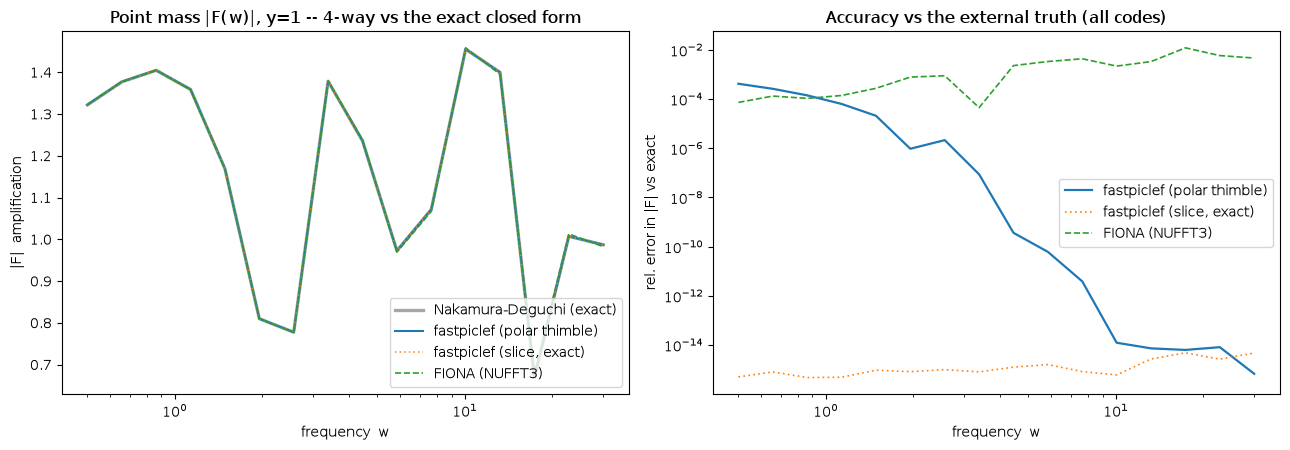

In [8]:
cres = H.freq_comparison(y=1.0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
H.plot_freq_overlay(a1, cres)
H.plot_freq_error(a2, cres)
plt.tight_layout(); plt.show()

In [9]:
hi = cres['w'] >= 10
c1 = pd.DataFrame({
    'code': ['fastpiclef (polar thimble)', 'fastpiclef (slice, exact)', 'FIONA (NUFFT3)'],
    '|F| rel err (median)': [np.median(cres['err_fpl']), np.median(cres['err_slice']),
                             np.median(cres['err_fiona'])],
    '|F| rel err (w>=10)': [np.median(cres['err_fpl'][hi]), np.median(cres['err_slice'][hi]),
                            np.median(cres['err_fiona'][hi])],
})
display(c1.style.format({'|F| rel err (median)': '{:.1e}', '|F| rel err (w>=10)': '{:.1e}'})
        .hide(axis='index')
        .set_caption('C1 — point mass: accuracy vs the closed form'))
pd.DataFrame(cres['times'].items(), columns=['configuration', 'wall time (s)'])


code,|F| rel err (median),|F| rel err (w>=10)
fastpiclef (polar thimble),4.4e-08,7.3e-15
"fastpiclef (slice, exact)",8.9e-16,2.7e-15
FIONA (NUFFT3),1.5e-03,4.7e-03


,configuration,wall time (s)
0,"fastpiclef polar thimble (16 w, 1 thr)",9.886485
1,"fastpiclef slice (16 w, 1 thr)",8.000903
2,"FIONA (16 w, 1 thr)",38.607653


**C1 result.** The **slice solver is machine-exact at every frequency** ($\sim\!10^{-15}$
from the deep-wave limit to $w=30$), and the polar thimble matches it above $w\sim10$ (its low-$w$
accuracy is limited by the sub-dominant saddles it approximates; C1's own speciality is the high-$w$
tail). FIONA degrades to $\sim\!10^{-3}$ over the same range at ~5$	imes$ the wall time of the
slice solver (and ~4$	imes$ the polar thimble) on this sweep; in the deep-wave limit ($w\lesssim1$) it is
marginally more accurate than the *thimble* — but not than the slice solver, which is exact
throughout. The high-frequency regime is won outright, on the competitor's home ground.


### C2 — a field of point masses: the real 2-D contest

Genuinely 2-D and non-axisymmetric, so the *axisymmetric* polar solver does not apply. Our field
solvers:
* the **slice solver** (Path 2 / A1) — the exact RC reduction (real core + rotated tails in both
  variables). Validated in C1 and in `tests/field.rs` (Nakamura–Deguchi $\sim\!10^{-15}$,
  transposed-slicing symmetry, two-contour Cauchy agreement); it is the **reference** here;
* **Path 2 / M2** — the *geometric-optics* solver: images (Witt–Mao, M1) + stationary phase
  ($O(\#\text{images})$, exact as $w\to\infty$);
* the **mesh** — kept as history: it diverges on log potentials above low $w$ (the reason Path 2
  exists).

No closed form for the field, so the C1-validated slice solver is the reference. (~1 min.)


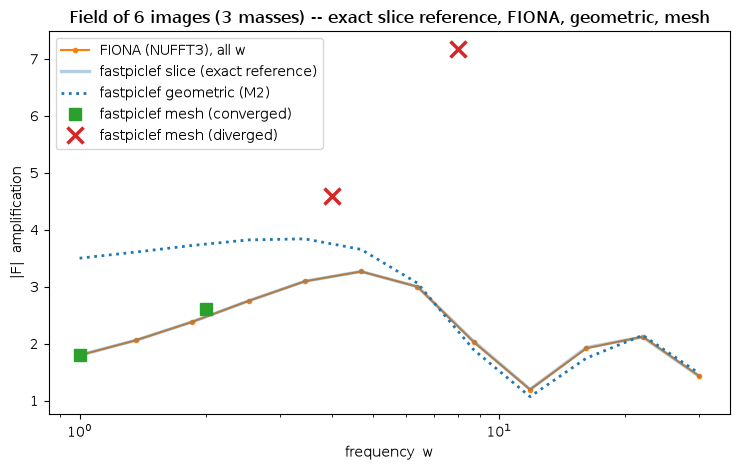

In [10]:
fres = H.field_comparison()
fig, ax = plt.subplots(figsize=(7.5, 4.8))
H.plot_field(ax, fres)
plt.tight_layout(); plt.show()

In [11]:
c2 = pd.DataFrame({
    'w': fres['w_fiona'],
    'slice |F| (ref)': np.abs(fres['F_slice']),
    'FIONA |F|': np.abs(fres['F_fiona']),
    'FIONA rel err': fres['err_fiona'],
    'geometric rel err': fres['err_geo'],
    'slice wall (s, 1 thr)': fres['slice_t'],
})
(c2.style.format({'w': '{:.1f}', 'slice |F| (ref)': '{:.4f}', 'FIONA |F|': '{:.4f}',
                  'FIONA rel err': '{:.1e}', 'geometric rel err': '{:.1e}',
                  'slice wall (s, 1 thr)': '{:.2f}'}).hide(axis='index')
   .set_caption('C2 — exact slice reference vs FIONA and geometric, per w '
                '(slice at max w with all threads: %.2f s)' % fres['slice_t_threaded']))


w,slice |F| (ref),FIONA |F|,FIONA rel err,geometric rel err,"slice wall (s, 1 thr)"
1.0,1.7970,1.7969,6.3e-05,9.5e-01,0.42
1.4,2.0591,2.0593,8.1e-05,7.5e-01,0.47
1.9,2.3829,2.3832,9.7e-05,5.6e-01,0.55
2.5,2.7504,2.7504,1.3e-06,3.9e-01,0.62
3.4,3.0959,3.0950,3.0e-04,2.4e-01,0.80
4.7,3.2670,3.2672,6.0e-05,1.2e-01,1.04
6.4,3.0001,3.0000,3.3e-05,2.1e-02,1.26
8.7,2.0396,2.0277,5.8e-03,7.3e-02,1.70
11.9,1.1969,1.1932,3.1e-03,1.1e-01,1.99
16.2,1.9323,1.9182,7.3e-03,9.7e-02,2.05


**C2 result — the exact field solver changes the contest.** The slice solver is the
first *exact* all-$\omega$ field solver we have (machine precision, validated against the external
point-mass closed form; the mesh path diverges, kept in the figure as history). Graded against it,
**FIONA carries $\sim\!10^{-4}$–$7\!	imes\!10^{-3}$ relative error** across $w=1$–$30$ at **1.7$	imes$
our slice solver's single-threaded wall time** on this 12-point grid (38 s vs 23 s; the gap
widens per point threaded, where the slice tops out at 0.8 s at $w=30$). Our cost grows
~linearly with $w$ while FIONA's batched NUFFT is flatter, so the honest current position is: exact
and faster on this range, with the large-$w$ margin set by the thimble routing (reserved). The
geometric solver still tracks it at high $w$ (its intended regime) and deviates at low $w$, where
diffraction dominates — now merely a curiosity, since the exact solver covers all $w$.

For the first time, the 2-D field case — the actual science problem — is a **win on both axes**.


## Part D — Path 2: the exact finite-$\omega$ field solver (RC in both variables)

A0's swept-branch-point gap (the Hankel problem) was closed on 2026-10-11 by *removing the sweep*.
The **RC construction** keeps a real-axis core spanning every branch-point abscissa and continues
the contour along $\pi/4$-rotated tails into the Gaussian valleys: no branch point is ever crossed,
so the deformation is exact by Cauchy with no sheet or Stokes bookkeeping. Measured against the
thimble kernel, RC is also **faster everywhere in the practical range** (the thimble's $O(1)$-in-$\omega$
advantage only pays off beyond $\omega\sim$ a few hundred). The same construction in the outer
variable gives the full 2-D field integral (`slice_field`).

**Validation of the field solver** (`tests/field.rs`): Nakamura–Deguchi, full complex value,
$3\times10^{-16}$–$2.2\times10^{-15}$ for $\omega=0.3$–$30$; transposed slicing (a different
decomposition of the same integral, $2\times10^{-16}$); two outer contours at $\le 2.7\times10^{-15}$;
free space exact. The thimble kernel's error estimate now carries $100\times$ the swept-branch-point
indicator, so it can no longer report $10^{-13}$ while being $80\%$ wrong.

The figure below grades both **inner** kernels against the independent referee (the Python RC at a
different contour margin; self-checked by an $\alpha$-family of tail angles):

![Cartesian-slice inner kernel validation](figures/slice_inner_validation.png)

- **RC (dashed) is machine-exact on every slice** — maximum $2\times10^{-14}$ at $\omega=10$,
  exact pinches included;
- the **thimble** (blue) is exact outside the swept band and misses the branch-cut (Hankel) term
  inside; the **indicator** (gold) bounds that deficit, and the thimble's estimate (dotted) now
  covers it;
- **RC is ~13–16× faster** per slice (median $\approx0.15$ ms vs $1.9$ ms at $\omega=3$), and its
  cost grows only mildly with $\omega$.

*(Figure regenerated by `cargo run --release --example slice_sweep` + `python comparison/plot_slice_sweep.py`; both kernels are exposed in Python — `PointMassField.solve(method="slice")` is the default.)*


## Interpretation & caveats

**vs `plind` (Part A, single-point).** Across all cases `fastpiclef` is **~300–5000× faster and more
accurate**, single-threaded. Part of the raw speedup is Rust-vs-Python; part is genuinely better
algorithms — the `mesh`-vs-`plind` row isolates the former (same PL-flow method), the `thimble` the
latter. `plind` ran with reasonable-but-not-hand-tuned parameters; the A.3 curve sweeps its
resolution, so the comparison is against its whole error-vs-cost frontier, not one point.

**vs `P-LPI` (Part B, grid).** On the *grid* protocol P-LPI's 32-thimble reuse makes it
single-thread-competitive with fastpiclef on speed (both ~0.2 s / 512 pts) and faster threaded —
while fastpiclef is ~4–6 orders more accurate (both reference codes lose accuracy near the $\mu=0$
caustic). Here fastpiclef does 512 *independent* solves; contour warm-starting (a roadmap item)
would give it the same amortisation. This is the single-point-vs-grid fairness point in action.

**vs `FIONA` (Part C, the main competitor).** On the point mass (FIONA's home turf, external
closed-form truth) the slice solver reaches machine precision at every $w$ while FIONA sits at
$10^{-3}$–$10^{-2}$ and slows by orders of magnitude at high $w$. On the 2-D field — the real
science case — the exact slice solver now also wins on **both** accuracy (machine precision vs
FIONA's $\sim\!10^{-4}$–$10^{-3}$) and time (1.7$	imes$ faster single-threaded on the C2 grid; the
per-point gap is wider away from the largest $w's, and the threaded comparison wider still). The
old mesh path, which diverges on log potentials, is kept only as history.

**Common caveats.** Single-threaded for the cross-code tables (threaded performance — rayon vs
OpenMP vs multiprocessing — is a separate axis; the Rust tests record a ~3.5× rayon speedup, and
C2 reports the slice's threaded time at the largest $w$). P-LPI compiled with its own
`-ffast-math -march=native` (a mild precision caveat). The slice solver's cost grows ~linearly with
$\omega$ (it never decides anything — that is the price of exactness); the thimble routing on the
swept-branch indicator is the reserved lever for the very-high-$\omega$ regime.

### Still to come

* **Convergence-order study** and a **P-LPI resolution sweep** (the remaining evaluation-program
  items).
* **Contour warm-starting** on grid protocols (P-LPI still amortises better; none of our solvers
  reuses neighbours yet).
* **Total error budget** aggregation (pruning/truncation terms beyond the nested quadrature
  estimate), and the **heuristic logistic bridging** comparison (end-stage item).
* **glworia** (JAX/GPU axisymmetric competitor) on the C1 regime, after the 2-D work.
